# Modelo de estimativa de peso

**Objetivo:** estimar o peso (g) de um alimento a partir da área que ocupa na foto.

Até agora o peso era calculado com uma fórmula com valores escolhidos à mão:

```
peso = área (cm²) × altura (cm) × densidade (g/cm³)
```

A altura e a densidade foram ajustadas para uma foto de teste e falhavam noutras fotos.
Aqui substituímos esses valores por valores **aprendidos com dados reais**.

**Dados:** [Nutrition5k](https://github.com/google-research-datasets/Nutrition5k) (Google, CC BY 4.0) —
pratos de uma cantina fotografados de cima, com o peso real de cada ingrediente medido em balança.
Usamos só os **pratos com um único ingrediente**: nesses sabemos exatamente o que está na foto e quanto pesa.

Os dados são preparados por:
- `scripts/descarregar_nutrition5k.py` — descarrega metadados e fotos
- `scripts/extrair_areas.py` — corre o modelo de segmentação (YOLO) nas fotos e mede a área da comida

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

PASTA_N5K = os.path.join('..', 'dados', 'nutrition5k')

# Do artigo do Nutrition5k: câmara a 35,9 cm, cada píxel = 5,957e-3 cm²
AREA_PIXEL_CM2 = 5.957e-3

## 1. Carregar os dados

In [2]:
ingredientes = pd.read_csv(os.path.join(PASTA_N5K, 'ingredientes.csv'))
areas = pd.read_csv(os.path.join(PASTA_N5K, 'areas.csv'))

# Pratos com um só ingrediente
n_ingredientes = ingredientes.groupby('prato').size()
um_ingrediente = n_ingredientes[n_ingredientes == 1].index

df = ingredientes[ingredientes['prato'].isin(um_ingrediente)].merge(areas, on='prato')
df['area_cm2'] = df['area_px'] * AREA_PIXEL_CM2
print(f'Pratos de um só ingrediente com foto: {len(df)}')
df.head()

Pratos de um só ingrediente com foto: 910


,prato,ingrediente,peso_g,hc_g,area_px,n_detecoes,classes_detetadas,area_cm2
0,dish_1558372433,deprecated,143.0,0.429,0,0,NaN,0.000000
1,dish_1565972591,chicken apple sausage,122.0,3.660,26617,1,potato,158.557469
2,dish_1568649312,berries,78.0,10.920,11312,6,"blueberry, blueberry, strawberry, raspberry, c...",67.385584
3,dish_1562862493,scrambled eggs,134.0,2.144,37075,1,rice,220.855775
4,dish_1558549008,cherry tomatoes,115.0,4.485,23333,3,"tomato, tomato, carrot",138.994681


## 2. Limpeza

- Fotos onde o YOLO não detetou comida (área = 0) não servem para aprender a relação área → peso.
- O ingrediente `deprecated` é um registo inválido do próprio dataset.
- Há pesos impossíveis (ex: um prato de azeitonas com 7974 g). Removemos pratos acima de 1 kg.
- Há áreas impossíveis: às vezes o YOLO marca a mesa inteira como comida (ex: uma pera com 1215 cm²).
  Nenhum alimento ocupa mais do que um prato inteiro (26 cm de diâmetro ≈ 530 cm²), por isso removemos
  áreas acima de 550 cm².

In [3]:
antes = len(df)
df = df[df['area_px'] > 0]
print(f'Sem deteção: {antes - len(df)} removidos')

antes = len(df)
df = df[df['ingrediente'] != 'deprecated']
print(f'Ingrediente inválido: {antes - len(df)} removidos')

print('\nPratos acima de 1 kg:')
print(df[df['peso_g'] > 1000][['prato', 'ingrediente', 'peso_g', 'area_cm2']].to_string(index=False))
df = df[df['peso_g'] <= 1000]

antes = len(df)
df = df[df['area_cm2'] <= 550]
print(f'Área maior do que um prato (erro de segmentação): {antes - len(df)} removidos')

print(f'\nFicam {len(df)} pratos')

Sem deteção: 156 removidos
Ingrediente inválido: 7 removidos

Pratos acima de 1 kg:
Empty DataFrame
Columns: [prato, ingrediente, peso_g, area_cm2]
Index: []
Área maior do que um prato (erro de segmentação): 36 removidos

Ficam 711 pratos


## 3. Agrupar os ingredientes por categoria

Os ingredientes do Nutrition5k estão em inglês e são muito específicos. Agrupamo-los nas **mesmas
categorias da nossa tabela de alimentos** (`dados/tabela_alimentos.xlsx`). Assim, na app, o modelo recebe
a categoria do alimento detetado (ex: `rice` → "Arroz solto cozido" → "Cereais e pseudo-cereais").

Os ingredientes que não encaixam em nenhuma categoria ficam de fora.

In [4]:
CATEGORIA_DO_INGREDIENTE = {
    'Cereais e pseudo-cereais': ['white rice', 'brown rice', 'fried rice', 'wild rice', 'country rice',
                                 'pasta', 'noodles', 'rice noodles', 'oatmeal', 'corn on the cob',
                                 'quinoa', 'wheat berry'],
    'Batata': ['potatoes', 'roasted potatoes', 'sweet potato', 'yam', 'hash browns'],
    'Pão': ['bread', 'wheat bread', 'bagels', 'tortilla'],
    'Pratos mistos, cozinhados e outros': ['cheese pizza', 'pepperoni pizza', 'pizza'],
    'Fruta fresca': ['apple', 'grapes', 'cantaloupe', 'berries', 'strawberries', 'pears', 'watermelon',
                     'pineapple', 'honeydew melons', 'orange', 'banana', 'kiwi', 'blueberries',
                     'raspberries', 'blackberries', 'mango', 'peaches'],
    'Frutos amiláceos e oleaginosos': ['almonds', 'nuts', 'walnuts', 'cashews'],
    'Não contabilizar': ['bacon', 'cauliflower', 'cherry tomatoes', 'tomatoes', 'carrot', 'scrambled eggs',
                         'caesar salad', 'spinach (raw)', 'broccoli', 'sausage', 'mixed greens', 'egg whites',
                         'eggs', 'brussels sprouts', 'mushroom', 'chicken apple sausage', 'chicken', 'ham',
                         'fish', 'tofu', 'cucumbers', 'bell peppers', 'asparagus'],
}
ingrediente_para_categoria = {ing: cat for cat, lista in CATEGORIA_DO_INGREDIENTE.items() for ing in lista}

df['categoria'] = df['ingrediente'].map(ingrediente_para_categoria)
print(f'Sem categoria (ficam de fora): {df["categoria"].isna().sum()} pratos')
df = df.dropna(subset=['categoria'])

df['categoria'].value_counts()

Sem categoria (ficam de fora): 67 pratos


categoria
Não contabilizar                      291
Fruta fresca                          177
Pratos mistos, cozinhados e outros     70
Frutos amiláceos e oleaginosos         36
Cereais e pseudo-cereais               33
Batata                                 33
Pão                                     4
Name: count, dtype: int64

## 4. Explorar: a área está relacionada com o peso?

Se a relação fosse a mesma para todos os alimentos, os pontos formariam uma única linha.

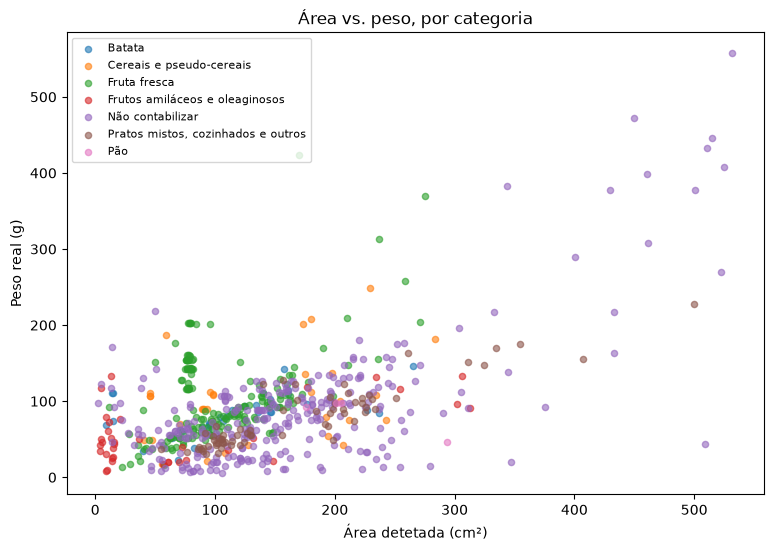

Correlação área vs. peso por categoria:
categoria
Batata                                0.51
Cereais e pseudo-cereais              0.35
Fruta fresca                          0.43
Frutos amiláceos e oleaginosos        0.54
Não contabilizar                      0.68
Pratos mistos, cozinhados e outros    0.91
Pão                                  -0.94


In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
for categoria, grupo in df.groupby('categoria'):
    ax.scatter(grupo['area_cm2'], grupo['peso_g'], label=categoria, alpha=0.6, s=20)
ax.set_xlabel('Área detetada (cm²)')
ax.set_ylabel('Peso real (g)')
ax.set_title('Área vs. peso, por categoria')
ax.legend(fontsize=8)
plt.show()

print('Correlação área vs. peso por categoria:')
print(df.groupby('categoria')[['area_cm2', 'peso_g']].corr().xs('area_cm2', level=1)['peso_g'].round(2).to_string())

## 5. Separar treino e teste

80% dos pratos para treinar, 20% guardados para avaliar. Os modelos nunca veem os pratos de teste
durante o treino. A separação mantém a proporção de cada categoria (`stratify`).

In [6]:
treino, teste = train_test_split(df, test_size=0.2, random_state=42, stratify=df['categoria'])
print(f'Treino: {len(treino)} pratos | Teste: {len(teste)} pratos')

Treino: 515 pratos | Teste: 129 pratos


## 6. Referência: a fórmula antiga

`peso = área × altura × densidade`, com os valores escolhidos à mão que estavam em `vision/detetor.py`
antes deste modelo (copiados aqui só para comparação). A altura e a densidade dependem da classe
que o YOLO detetou.

In [7]:
# Valores da versão antiga de vision/detetor.py
CATEGORIAS_FISICAS = {
    'grao_cozido':  {'altura_cm': 2.2, 'densidade': 1.10},
    'fritos_amido': {'altura_cm': 1.8, 'densidade': 0.65},
    'folhas':       {'altura_cm': 0.8, 'densidade': 0.30},
    'legume_polpa': {'altura_cm': 1.2, 'densidade': 0.60},
    'proteina':     {'altura_cm': 1.5, 'densidade': 1.00},
    'proteina_fina':{'altura_cm': 0.8, 'densidade': 1.00},
    'pao':          {'altura_cm': 3.0, 'densidade': 0.25},
    'padrao':       {'altura_cm': 1.5, 'densidade': 0.85},
}
MAPA_CATEGORIAS = {
    'rice': 'grao_cozido', 'pasta': 'grao_cozido', 'noodles': 'grao_cozido', 'corn': 'grao_cozido',
    'french fries': 'fritos_amido', 'potato': 'fritos_amido',
    'lettuce': 'folhas', 'cabbage': 'folhas', 'spinach': 'folhas', 'salad': 'folhas',
    'tomato': 'legume_polpa', 'onion': 'legume_polpa', 'cucumber': 'legume_polpa', 'carrot': 'legume_polpa',
    'egg': 'proteina_fina',
    'bread': 'pao',
    'steak': 'proteina', 'pork': 'proteina', 'chicken duck': 'proteina', 'fish': 'proteina',
    'sausage': 'proteina', 'fried meat': 'proteina', 'shrimp': 'proteina',
}

def formula_antiga(linha):
    classe_yolo = str(linha['classes_detetadas']).split(', ')[0]
    propriedades = CATEGORIAS_FISICAS[MAPA_CATEGORIAS.get(classe_yolo, 'padrao')]
    return linha['area_cm2'] * propriedades['altura_cm'] * propriedades['densidade']

previsoes = {'Fórmula antiga (valores manuais)': teste.apply(formula_antiga, axis=1)}

## 6b. Referência: ignorar a foto

Prevê sempre o peso médio da categoria no treino, sem olhar para a área.
Se um modelo não for melhor do que isto, a área da foto não está a ajudar.

In [8]:
peso_medio = treino.groupby('categoria')['peso_g'].mean()
previsoes['Peso médio da categoria (sem foto)'] = teste['categoria'].map(peso_medio).fillna(treino['peso_g'].mean())

## 7. Modelo A: gramas por cm², aprendido por categoria

A fórmula antiga era, no fundo, `peso = área × (altura × densidade)`, ou seja, um valor de
**gramas por cm²** para cada tipo de alimento. Em vez de o inventar, aprendemo-lo com os dados:
uma regressão linear sem ordenada na origem (0 cm² = 0 g), uma para cada categoria.

Para cada categoria, o valor que minimiza o erro quadrático é `Σ(área × peso) / Σ(área²)`.
Para categorias sem dados de treino (ex: Pão), usa-se o valor calculado com todos os pratos.

In [9]:
def gramas_por_cm2(dados):
    return (dados['area_cm2'] * dados['peso_g']).sum() / (dados['area_cm2'] ** 2).sum()

modelo_a = {
    'geral': gramas_por_cm2(treino),
    'por_categoria': treino.groupby('categoria').apply(gramas_por_cm2, include_groups=False).to_dict(),
}

def prever_modelo_a(modelo, area_cm2, categoria):
    return area_cm2 * modelo['por_categoria'].get(categoria, modelo['geral'])

previsoes['Modelo A (g/cm² por categoria)'] = [
    prever_modelo_a(modelo_a, a, c) for a, c in zip(teste['area_cm2'], teste['categoria'])
]

print('Gramas por cm² aprendidos:')
for categoria, valor in sorted(modelo_a['por_categoria'].items(), key=lambda x: x[1]):
    print(f'  {categoria:<36} {valor:.2f}')
print(f'  {"(geral)":<36} {modelo_a["geral"]:.2f}')
print('\nPara comparar, a fórmula antiga usava (altura × densidade):')
for tipo, p in CATEGORIAS_FISICAS.items():
    print(f'  {tipo:<36} {p["altura_cm"] * p["densidade"]:.2f}')

Gramas por cm² aprendidos:
  Pão                                  0.31
  Frutos amiláceos e oleaginosos       0.45
  Pratos mistos, cozinhados e outros   0.46
  Não contabilizar                     0.54
  Batata                               0.67
  Cereais e pseudo-cereais             0.70
  Fruta fresca                         0.97
  (geral)                              0.59

Para comparar, a fórmula antiga usava (altura × densidade):
  grao_cozido                          2.42
  fritos_amido                         1.17
  folhas                               0.24
  legume_polpa                         0.72
  proteina                             1.50
  proteina_fina                        0.80
  pao                                  0.75
  padrao                               1.27


## 8. Modelo B: Random Forest

Um modelo mais flexível, que pode aprender relações não lineares (ex: porções grandes mais altas).
Recebe a área e a categoria (convertida em colunas 0/1 com `OneHotEncoder`).

In [10]:
modelo_b = Pipeline([
    ('preparar', ColumnTransformer([
        ('categoria', OneHotEncoder(handle_unknown='ignore'), ['categoria']),
    ], remainder='passthrough')),
    ('rf', RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42)),
])
modelo_b.fit(treino[['area_cm2', 'categoria']], treino['peso_g'])

previsoes['Modelo B (Random Forest)'] = modelo_b.predict(teste[['area_cm2', 'categoria']])

## 9. Avaliação nos pratos de teste

- **Erro médio (g):** em média, quantos gramas a previsão falha (MAE).
- **Erro médio (%):** o mesmo, relativo ao peso real.
- **Erro médio de HC (g):** o que importa para a insulina. Calculado com os hidratos reais por grama
  de cada ingrediente, para medir só o efeito do erro de peso.

In [11]:
hc_por_grama = teste['hc_g'] / teste['peso_g']

resultados = []
for nome, prev in previsoes.items():
    prev = np.asarray(prev)
    erro = np.abs(prev - teste['peso_g'])
    resultados.append({
        'Abordagem': nome,
        'Erro médio (g)': erro.mean(),
        'Erro médio (%)': 100 * (erro / teste['peso_g']).mean(),
        'Erro médio de HC (g)': (erro * hc_por_grama).mean(),
    })

resultados = pd.DataFrame(resultados).set_index('Abordagem').round(1)
resultados

,Erro médio (g),Erro médio (%),Erro médio de HC (g)
Abordagem,,,
Fórmula antiga (valores manuais),103.8,209.4,14.5
Peso médio da categoria (sem foto),40.7,97.7,4.2
Modelo A (g/cm² por categoria),37.5,71.4,4.2
Modelo B (Random Forest),31.5,72.2,3.1


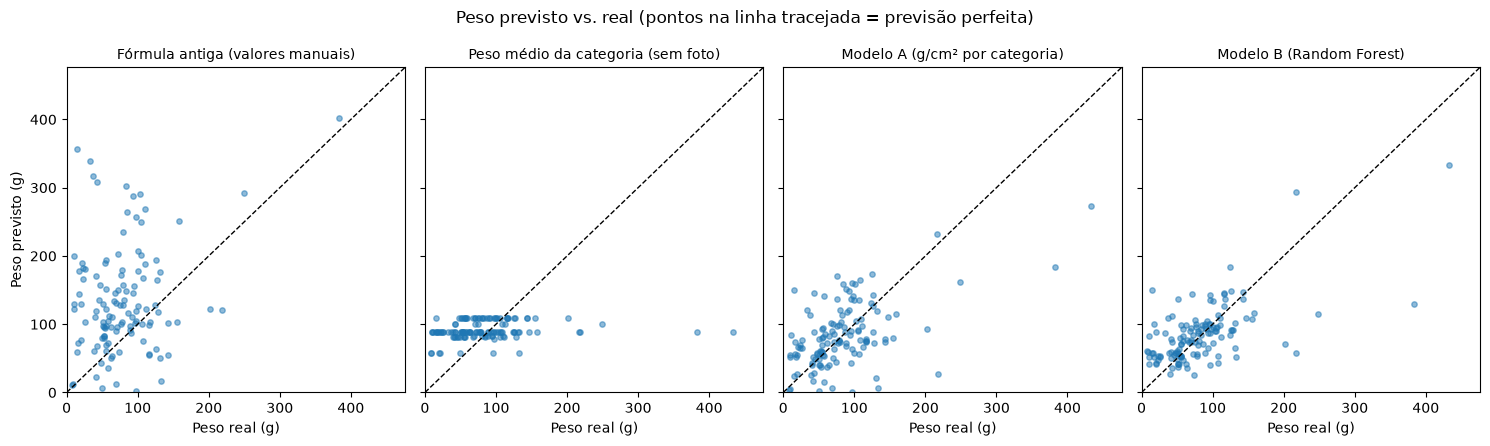

In [12]:
fig, eixos = plt.subplots(1, len(previsoes), figsize=(15, 4.5), sharex=True, sharey=True)
limite = teste['peso_g'].max() * 1.1
for ax, (nome, prev) in zip(eixos, previsoes.items()):
    ax.scatter(teste['peso_g'], prev, alpha=0.5, s=15)
    ax.plot([0, limite], [0, limite], 'k--', linewidth=1)  # previsão perfeita
    ax.set_title(nome, fontsize=10)
    ax.set_xlabel('Peso real (g)')
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
eixos[0].set_ylabel('Peso previsto (g)')
plt.suptitle('Peso previsto vs. real (pontos na linha tracejada = previsão perfeita)')
plt.tight_layout()
plt.show()

### Erro por categoria (Modelo A)

In [13]:
por_categoria = teste.assign(
    previsto=previsoes['Modelo A (g/cm² por categoria)'],
    erro_g=lambda d: (d['previsto'] - d['peso_g']).abs(),
).groupby('categoria').agg(pratos=('prato', 'count'), peso_medio=('peso_g', 'mean'), erro_medio_g=('erro_g', 'mean'))
por_categoria.round(1)

,pratos,peso_medio,erro_medio_g
categoria,,,
Batata,7,88.7,32.1
Cereais e pseudo-cereais,7,100.0,64.7
Fruta fresca,35,91.0,39.7
Frutos amiláceos e oleaginosos,7,48.1,39.7
Não contabilizar,58,83.7,39.6
"Pratos mistos, cozinhados e outros",14,66.3,11.1
Pão,1,97.0,33.9


## 10. Conclusões

| Abordagem | Erro médio (teste) | Média em 5 divisões treino/teste |
|---|---|---|
| Fórmula antiga (valores manuais) | ~104 g (~14,5 g HC) | — |
| Peso médio da categoria (sem foto) | ~41 g | ~42 g |
| Modelo A (g/cm² por categoria) | ~38 g | ~37 g |
| **Modelo B (Random Forest)** | **~32 g (~3,1 g HC)** | **~31 g** |

1. **A fórmula com valores manuais era o maior problema.** Os gramas/cm² inventados estavam muito
   longe dos medidos (ex: 2,42 g/cm² para arroz/massa contra ~0,70 aprendidos), e o erro era ~3x maior.
2. **A Random Forest é a melhor abordagem**, e foi a melhor nas 5 divisões treino/teste diferentes.
3. **A área ajuda, mas não resolve tudo.** Ignorar a foto já dá ~42 g de erro; a área baixa isso para ~31 g.
   Uma foto de cima não mostra a altura da comida (uma maçã inteira e uma fatia fina podem ter a mesma área).
4. **A limpeza dos dados foi essencial.** Em ~5% das fotos o YOLO marcou a mesa como comida; sem remover
   esses casos, o Modelo A ficava pior do que ignorar a foto.

**Limitações:**
- Porções de cantina, mais pequenas do que um prato de restaurante português. Para porções muito maiores
  do que as vistas no treino, a Random Forest não extrapola (fica perto do valor máximo que conhece).
- Poucos dados de Pão (4 pratos) e de Cereais/Batata (~33 cada).
- O conjunto de teste é pequeno (~130 pratos), por isso os valores exatos têm alguma incerteza.

## 11. Que modelo usar na app?

A Random Forest tem o menor erro no teste, mas o teste só tem pratos **parecidos com os do treino**
(porções de cantina). A app vai receber fotos de pratos portugueses, com porções diferentes.

Testámos os dois modelos com áreas medidas nas fotos de pratos reais da app (`prato.jpg`, `prato2.jpg`):

In [14]:
fotos_app = pd.DataFrame({
    'alimento': ['tomate', 'bife', 'arroz (prato.jpg)', 'arroz (prato2.jpg)'],
    'categoria': ['Não contabilizar', 'Não contabilizar', 'Cereais e pseudo-cereais', 'Cereais e pseudo-cereais'],
    'area_cm2': [3.7, 16.0, 40.9, 129.1],
})
fotos_app['Modelo A (g)'] = [prever_modelo_a(modelo_a, a, c) for a, c in zip(fotos_app['area_cm2'], fotos_app['categoria'])]
fotos_app['Random Forest (g)'] = modelo_b.predict(fotos_app[['area_cm2', 'categoria']])
fotos_app.round(0)

,alimento,categoria,area_cm2,Modelo A (g),Random Forest (g)
0,tomate,Não contabilizar,4.0,2.0,100.0
1,bife,Não contabilizar,16.0,9.0,89.0
2,arroz (prato.jpg),Cereais e pseudo-cereais,41.0,29.0,83.0
3,arroz (prato2.jpg),Cereais e pseudo-cereais,129.0,91.0,75.0


A Random Forest dá resultados sem sentido fora do que viu no treino: um pedaço de tomate com 3,7 cm²
"pesa" quase 100 g, e o arroz com **mais** área recebe **menos** peso. Uma Random Forest não extrapola:
para áreas fora do intervalo do treino devolve a média de casos parecidos que encontrou.

O Modelo A dá sempre mais peso a mais área e escala de forma razoável para porções maiores.

**Decisão:** a app usa o **Modelo A**. Perde ~6 g de erro no teste (37 g contra 31 g), mas comporta-se
de forma previsível em fotos novas, e num valor que influencia doses de insulina isso é mais importante.
Também é o mais fácil de explicar: é a fórmula antiga com os gramas por cm² aprendidos em vez de inventados.

## 12. Guardar o modelo final

Os gramas por cm² são calculados outra vez com **todos** os pratos (treino + teste) e guardados em
`modelos/gramas_por_cm2.json`, o ficheiro que a app usa.

In [15]:
modelo_final = {
    'geral': gramas_por_cm2(df),
    'por_categoria': df.groupby('categoria').apply(gramas_por_cm2, include_groups=False).round(3).to_dict(),
}
modelo_final['geral'] = round(modelo_final['geral'], 3)

os.makedirs(os.path.join('..', 'modelos'), exist_ok=True)
with open(os.path.join('..', 'modelos', 'gramas_por_cm2.json'), 'w', encoding='utf-8') as f:
    json.dump(modelo_final, f, ensure_ascii=False, indent=2)
modelo_final

{'geral': np.float64(0.585),
 'por_categoria': {'Batata': 0.62,
  'Cereais e pseudo-cereais': 0.652,
  'Fruta fresca': 0.942,
  'Frutos amiláceos e oleaginosos': 0.418,
  'Não contabilizar': 0.542,
  'Pratos mistos, cozinhados e outros': 0.462,
  'Pão': 0.348}}